| | |
| --- | --- |
| Name: | Maarten Hemme |
| Student number: |  S3743020 |
| | |
| Name: | (...) |
| Student number: | (...) |
| | |

# PET Bootcamp - Differential Privacy Assignment

- This assignment consists of four tasks. 
- For each task, give results in the corresponding section.
- You cannot use Differential Privacy libraries such as diffprivlib or opendp for this assignment.
- Use the numpy, pandas and matplotlib libraries as much as possible (for instance for numpy.random.laplace)
- The use of AI tools for Python specific issues (including using libraries such as numpy, pandas and matplotlib) is allowed. When relevant, provide the prompts that you used.
- Do not use AI tools for differential privacy specific issues.
- Write your names and student numbers in the above table.
- Submit on Canvas

**Grading rubric**

|| 3 Pt | 2 Pt | 1 Pt | 0 Pt
-|-|-|-|-
Task 1 | | Correct solution, concise and clear discussion | Correct solution, but discussion/explanation not clear | Incorrect and/or no discussion/explanation
Task 2 | | Correct solution, with good connection to theory from class | Correct solution, limited/no connection to theory | Incorrect and/or no discussion/explanation
Task 3 | Correct solution, concise and clear discussion | Mostly correct solution | Partially correct solution | Incorrect and/or no discussion/explanation
Task 4 | Both mechanisms correct, discussion shows understanding of theory | Both mechanisms correct | One mechanism correct | Incorrect and/or no discussion/explanation


## Setup

This section loads the dataset you'll use throughout as well as a few suggested libraries. Familiarize yourself with the data structure.

In [153]:
# Imports

# - We'll use a dataset from the UCI ML repository.
# - Install ucimlrepo package if you haven't already (!pip install ucimlrepo)
from ucimlrepo import fetch_ucirepo 

# - You cannot use DP libraries such as diffprivlib or opendp for this assignment. Implement the mechanisms from scratch using only standard libraries such as numpy, pandas, etc.
# - The following are recommended:
import numpy as np # for numerical computations and for generating random variables
import pandas as pd # for data manipulation
import matplotlib.pyplot as plt # for plotting and visualization

In [154]:
# Load data

# - We'll use the Wine quality dataset (https://archive.ics.uci.edu/dataset/186/wine+quality) from the UCI ML repository.
# - The dataset contains various physicochemical properties of red and white wines, along with quality ratings.

# Fetch the dataset
wine_quality = fetch_ucirepo(id=186) 
  
# Select the red wines
red_wine_mask = wine_quality.data.original['color'] == 'red'
X = wine_quality.data.original[red_wine_mask][wine_quality.data.features.columns]

# The dataset also has an additional feature 'quality', which is intended to be used as a goal for a regression. We will not use it.

# To get an idea on the data in X:
print("Dataset shape:", X.shape)
print("\nFirst few samples:")
print(X.head())


Dataset shape: (1599, 11)

First few samples:
   fixed_acidity  volatile_acidity  citric_acid  residual_sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free_sulfur_dioxide  total_sulfur_dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  
0      9.4  
1      9.8  
2

## Task 1

### Assignment

- Implement a mechanism that reports the number of red wines that have a 'fixed_acidity' of more than 8.0. Make sure that the mechanism is differentially private with ε=0.1 and δ=0.
- Execute the mechanism 100 times and visualize the results in a histogram (so we use the histogram to validate/analyze the mechanism itself).
- Discuss your results (at most 100 words). Include in this discussion:
    * The actual number of red wines that have a 'fixed_acidity' of more than 8.0,
    * The shape of the histogram,
    * Variance and sensitivity.

In [155]:
x1 = X[X.columns[0:5]]
x2 = X[X.columns[0:5]]

In [156]:
wine_with_fixed_acidity = X[X["fixed_acidity"] > 8]
count_wine_with_fixed_acidity = wine_with_fixed_acidity.shape[0]

In [157]:
acidity_mean = X["fixed_acidity"].mean()
sensitivity = 1
target_acidity_mean = wine_with_fixed_acidity["fixed_acidity"].mean()
print(acidity_mean)
print(target_acidity_mean)

8.31963727329581
9.771120107962213


In [158]:
epsilon = 0.1
scale = sensitivity / epsilon

In [159]:
laplace_result = np.random.laplace(0, scale, 100)
print(laplace_result)

[ -4.94237945   5.51004103  -7.42282189  18.29303752 -28.17910768
  -1.06374396  15.97256247  20.91301456   0.99013555  -8.60025919
  -0.96392088 -10.95595634  -4.7895011   -3.21630497   6.59954235
   2.16006669  18.57996667  -3.56711882 -12.95285734  -7.33563492
   4.10183882 -25.13240761   3.43494086  -1.93764502  -9.86763279
   1.28225802  -2.65916172  17.80128952 -16.4324869  -15.47951498
 -23.63151752  20.08944268   1.18964944  -0.27931863  -3.11115053
 -32.95891964  -6.88266908 -11.06097012  -7.72821779  -8.61321131
 -17.9961375    2.38808786  -4.08905217  -3.12443204  12.46470964
 -20.42199619   8.04516075   5.33426394 -17.24681178  -6.55169935
 -14.73936712  -8.32503838   8.91456966   0.95448761  -0.71971694
   4.9496565   33.93513509  10.57121049  -1.42261745  -2.59727857
   1.43307367  -0.40361464  17.22262603  13.61432992   5.49042504
   2.7329627    0.58651094  -5.13042257 -10.35422208  27.70274869
  14.91280028  20.45501125   1.15389196  -0.0936391    6.3194361
 -25.485819

In [160]:
mechanism = laplace_result + count_wine_with_fixed_acidity
print(f"Laplace result: {laplace_result}")
print(f"Mechanism: { laplace_result + count_wine_with_fixed_acidity}")

Laplace result: [ -4.94237945   5.51004103  -7.42282189  18.29303752 -28.17910768
  -1.06374396  15.97256247  20.91301456   0.99013555  -8.60025919
  -0.96392088 -10.95595634  -4.7895011   -3.21630497   6.59954235
   2.16006669  18.57996667  -3.56711882 -12.95285734  -7.33563492
   4.10183882 -25.13240761   3.43494086  -1.93764502  -9.86763279
   1.28225802  -2.65916172  17.80128952 -16.4324869  -15.47951498
 -23.63151752  20.08944268   1.18964944  -0.27931863  -3.11115053
 -32.95891964  -6.88266908 -11.06097012  -7.72821779  -8.61321131
 -17.9961375    2.38808786  -4.08905217  -3.12443204  12.46470964
 -20.42199619   8.04516075   5.33426394 -17.24681178  -6.55169935
 -14.73936712  -8.32503838   8.91456966   0.95448761  -0.71971694
   4.9496565   33.93513509  10.57121049  -1.42261745  -2.59727857
   1.43307367  -0.40361464  17.22262603  13.61432992   5.49042504
   2.7329627    0.58651094  -5.13042257 -10.35422208  27.70274869
  14.91280028  20.45501125   1.15389196  -0.0936391    6.319

### Solution

Write your code/solution/explanation for Task 1 in this subsection. Add code/markdown cells as you see fit.

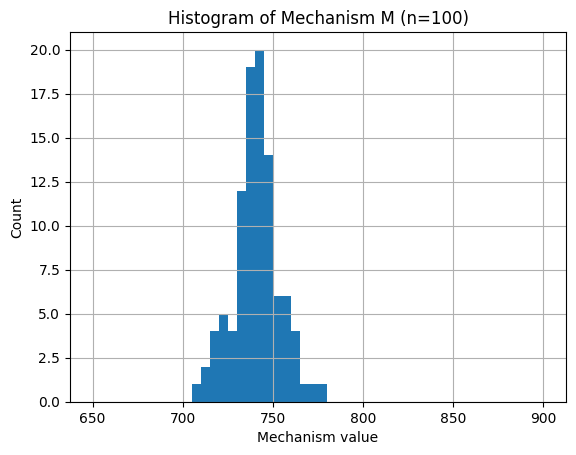

The actual number of red wines that have a 'fixed+acidity' of more than 8.0:  741
Variance: 200.0
Sensativity: 1


In [161]:
plt.hist(mechanism, range=(650, 900), bins=50)
plt.title("Histogram of Mechanism M (n=100)")
plt.xlabel("Mechanism value")
plt.ylabel("Count")
plt.grid(True)
plt.show()
print(f"The actual number of red wines that have a 'fixed+acidity' of more than 8.0:  {wine_with_fixed_acidity.shape[0]}")
print(f"Variance: {2 * pow(scale, 2)}")
print(f"Sensativity: {sensitivity}")

## Task 2

### Assignment

- Write a function that returns a differentially private histogram of the 'fixed_acidity' of red wines. Use ε=0.1 and δ=0.
- Create 16 bins of width 1 in the range [0,16] and make sure that the reported count in each bin is differentially private.
- In your results include three differentially private histograms (ε=0.1 and δ=0).
- Briefly explain your solution and discuss, for instance:
    * Did you add noise to each bin independently? If so, what does composition theory tell you about the total privacy budget?
    * Did you allow for bins with negative counts? Could you have made a different choice? Relate this to the postprocessing theorem.
    * Does the total number of observations in your histogram equal the number of rows in the dataset?

In [162]:
t2_bins = []
t2_amount_of_bins = 16

# Order the real values into 16 bins
for i in range(t2_amount_of_bins):
    t2_bins.append( X.loc[ (i < X["fixed_acidity"]) & (X["fixed_acidity"] <= i+1) ].shape[0]  )

In [163]:
t2_epsilon = 0.1
t2_sensitivity = 1 # Deze klopt nog neit
t2_scale = t2_sensitivity / t2_epsilon

In [164]:
t2_laplace_result = np.random.laplace(0, t2_scale, 16)
print(laplace_result)

[ -4.94237945   5.51004103  -7.42282189  18.29303752 -28.17910768
  -1.06374396  15.97256247  20.91301456   0.99013555  -8.60025919
  -0.96392088 -10.95595634  -4.7895011   -3.21630497   6.59954235
   2.16006669  18.57996667  -3.56711882 -12.95285734  -7.33563492
   4.10183882 -25.13240761   3.43494086  -1.93764502  -9.86763279
   1.28225802  -2.65916172  17.80128952 -16.4324869  -15.47951498
 -23.63151752  20.08944268   1.18964944  -0.27931863  -3.11115053
 -32.95891964  -6.88266908 -11.06097012  -7.72821779  -8.61321131
 -17.9961375    2.38808786  -4.08905217  -3.12443204  12.46470964
 -20.42199619   8.04516075   5.33426394 -17.24681178  -6.55169935
 -14.73936712  -8.32503838   8.91456966   0.95448761  -0.71971694
   4.9496565   33.93513509  10.57121049  -1.42261745  -2.59727857
   1.43307367  -0.40361464  17.22262603  13.61432992   5.49042504
   2.7329627    0.58651094  -5.13042257 -10.35422208  27.70274869
  14.91280028  20.45501125   1.15389196  -0.0936391    6.3194361
 -25.485819

In [165]:
t2_mechanism = []
for i in range(t2_amount_of_bins):
    t2_mechanism.append( t2_laplace_result[i] + t2_bins[i]  )

print(t2_mechanism)

[14.817660068436155, 5.7239190206846, -1.238254053785531, 8.675695922460795, -2.360279455651332, 4.695674940756334, 278.9207555037286, 465.751165080824, 281.3091849173822, 190.16235303991948, 119.49532775014411, 66.19177446212073, 41.812506826335685, 11.866440868228548, -10.11483388727913, 3.086524561808914]


### Solution

Write your code/solution/explanation for Task 2 in this subsection. Add code/markdown cells as you see fit.

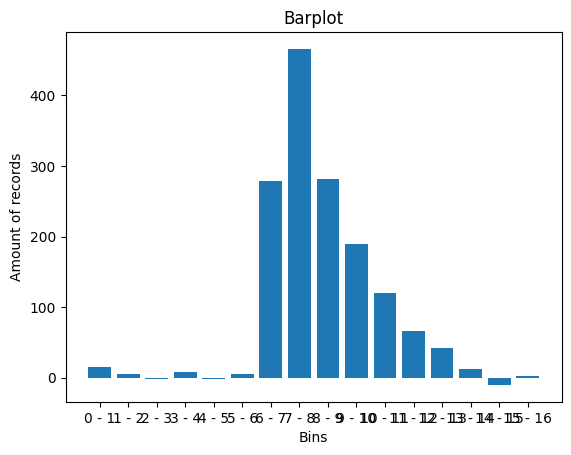

In [173]:
labels = []
for i in range(t2_amount_of_bins):
    labels.append(f"{i} - {i+1}")

plt.bar(labels, t2_mechanism)
plt.title('Barplot')
plt.xlabel('Bins')
plt.ylabel('Amount of records')
plt.show()

## Task 3

### Assignment

- In this task:
    * If you are missing information (domain knowledge on red wines or chemistry) use may use web searches or a LLM. If you do, explicitly report on the additional information that you are using in your solution and on the references/prompts that you used.
    * Assume that the number of rows is publicly known and use the subsitute model to compute sensitivity. 
- Implement a Laplace mechanisms that returns the differentially private average of the 'fixed_acidity'. Use ε=0.1.

### Solution

Write your code/solution/explanation for Task 3 in this subsection. Add code/markdown cells as you see fit.

## Task 4

### Assignment

- In this task:
    * If you are missing information (domain knowledge on red wines or chemistry) you may use web searches or a LLM. If you do, explicitly report on the additional information that you are using in your solution and on the references/prompts that you used.
    * Assume that the number of rows is publicly known and use the subsitute model to compute sensitivity. 
    * There's no need to copy explanation/justification from your solution to Task 3 if there is overlap.
- Implement two mechanisms that return a differentially private average for each of the features in the dataset:
    * Both mechanisms simultaneously return all differentially private averages.
    * Build these mechanisms using the Laplace mechanism and use overall/total privacy budget ε=0.5.
    * Base the first mechanism on sequential composition, by equally diving the privacy budget over all features and by computing a sensitivity per feature.
    * For the second mechanism, interpret this as a vector-valued query in which you use L1 sensitivity. 
- Report results (at most 4 figures and at most 100 words) that explain the difference between the mechanisms. (Don't report histograms of multiple outputs of one mechanism, but instead compare the values of the variances of the noise for each feature.)

### Solution

Write your code/solution/explanation for Task 4 in this subsection. Add code/markdown cells as you see fit.